# Building a catalog at 1.6 < z < 2.0

Notebook 01 for 1.6 < z < 2.0, with the same thresholds, base catalog, rescaling and doublet rule. Hα leaves the grism
at z = 1.94 (19 300 Å), and [O III] λ5007 carries the range to z = 2.0. The catalog here is therefore of every galaxy
(`line="all"`): Hα and [O III] emitters together, each with the redshift of the line it was identified by.
`line="Ha"` or `line="OIII_5007"` would keep one of them only.

Run it on a CPU node, from the package directory: `sbatch scripts/run_notebook.sh notebooks/02_catalog_z1p6_2p0.ipynb`
(about 3 minutes). The catalogs go to `$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>


## Step 1: the proposal

The sample is every detected galaxy at 1.6 < z < 2.0. A potential interloper is a single line that, taken for one of the
lines that are single inside the range, gets a redshift inside it. The panels are as in notebook 01: (a) the
single-line fraction inside the range, (b) each potential interloper at its own redshift, (c) the potential interlopers
at the redshift they would get, as a share of the catalog if every one were taken. The last lines print what `line="Ha"` and
`line="OIII_5007"` would hold.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 31 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        11,446,804 detected galaxies at 1.6 ≤ z < 2.0 (4,440 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  share¹
  ─────────  ────────  ──────
  all         369,242  3.23 %
  OIII_5007   205,199  1.79 %
  Ha          164,043  1.43 %
  ¹ of the 11,446,804 galaxies detected at 1.6 ≤ z < 2.0 (true redshift)

── Potential interlopers ───────────────────────────────────────────────────────────────────────────
  single lines that, taken for a line that is s

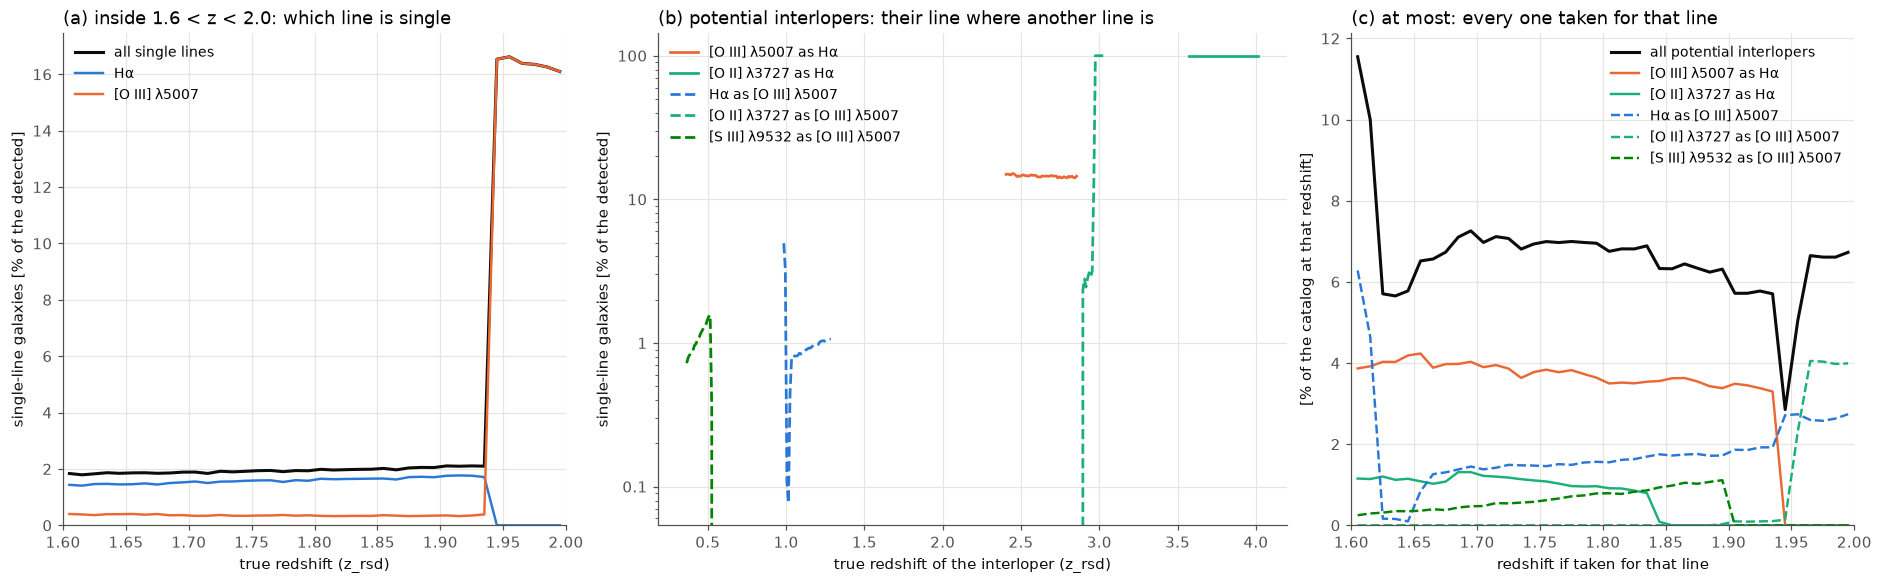

line="Ha": 10,377,362 galaxies with Ha detected at 1.6-2.0, before interlopers
line="OIII_5007": 11,280,740 galaxies with OIII_5007 detected at 1.6-2.0, before interlopers


In [2]:
proposal = base.make_proposal((1.6, 2.0), line="all", flux_limit=1.5e-16, secondary_flux_limit=6e-17, n_workers=N_WORKERS)
proposal.plot()
plt.show()
names = proposal.line_names
for line in ("Ha", "OIII_5007"):
    n = int(proposal.counts["n_line_det"][proposal.inside, names.index(line)].sum())
    print(f'line="{line}": {n:,} galaxies with {line} detected at 1.6-2.0, before interlopers')


For every galaxy at 1.6 < z < 2.0 (flux limits 1.5 / 0.6):

* **The sample** is 11.45 M detected galaxies (4,440 per deg²). `line="Ha"` would hold 10.38 M of them (Hα leaves the
  grism at z = 1.94), `line="OIII_5007"` 11.28 M.
* **(a) 3.2 % of the detected galaxies are single-line.** Below z = 1.94 it is about 2 %, mostly Hα. Above, it is 16 %,
  all [O III], once Hα has left the grism.
* **(b) Five potential pairs**:
  * [O III] at 2.41–2.85 taken for Hα: 420,599 (163 per deg², 15 % of the detected galaxies there), at most 3.4 % of
    the catalog;
  * Hα at 0.98–1.29 taken for [O III]: 219,110 (85 per deg²), at most 1.8 %;
  * [O II] at 3.58–4.18 taken for Hα: 91,560 (36 per deg²), at most 0.75 %. [O II] is the only line in the bandpass
    there, so every detected galaxy is single-line;
  * [S III] λ9532 at 0.37–0.58 (61,908) and [O II] at 2.49–3.03 (34,668) taken for [O III].
* **(c) At most 6–7 % of the catalog** over most of the range, 11.6 % at z = 1.6, where Hα at z ≈ 1.0 passes for
  [O III], and 2.9 % at z = 1.94, where Hα leaves the grism; 6.8 % in all.

### S/N thresholds instead of flux limits

S/N ≥ 5 for one line and ≥ 2 for the others in the Roman grism (one hour, twice the minimum zodiacal light), for the size
of each galaxy.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 50 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5 (other lines S/N ≥ 2), size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x
                min zodi
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 31 % of the detected
                galaxies with both lines in the bandpass
  sample        18,297,899 detected galaxies at 1.6 ≤ z < 2.0 (7,097 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  share¹
  ─────────  ────────  ──────
  all         703,875  3.85 %
  OIII_5007   579,448  3.17 %
  Ha          124,427  0.68 %
  ¹ of the 18,297,899 galaxies detected at 1.6 ≤ z < 2.0 (true redshift)

── Potential interlopers ───────────────────────────────────────────────────

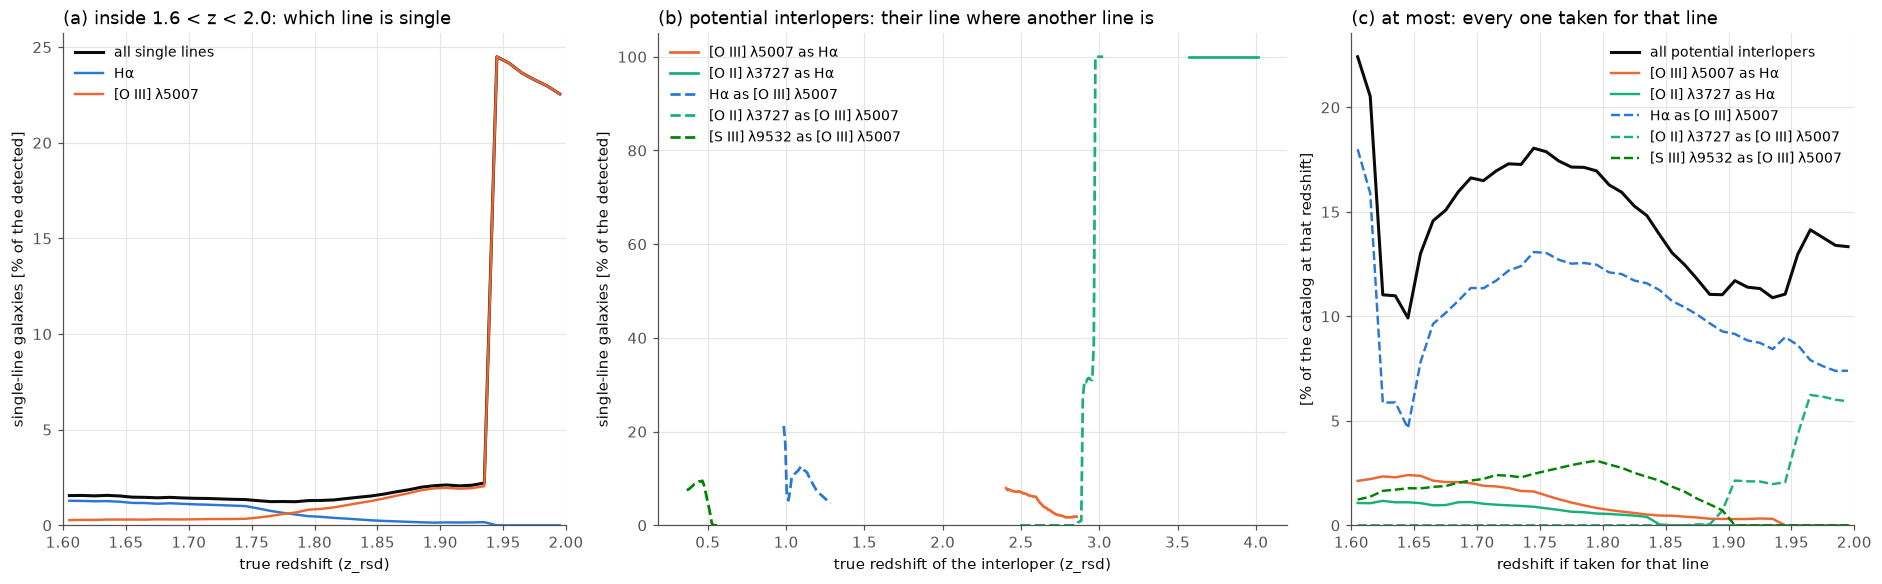

In [3]:
proposal_snr = base.make_proposal((1.6, 2.0), line="all", snr=5, secondary_snr=2, size="r50_disk_2d", n_workers=N_WORKERS)
proposal_snr.plot()
plt.show()


With S/N ≥ 5 / 2 and the size of each galaxy:

* **The sample** is 18.30 M galaxies (7,097 per deg²), 60 % more than with the flux limits. At these wavelengths the
  S/N limit of compact galaxies is fainter than 1.5 × 10⁻¹⁶.
* **(a) 3.9 % single-line**: [O III] in 3.2 %, Hα in 0.7 %.
* **(b) The largest pair is Hα at 0.98–1.29 taken for [O III]**: 2.30 M (890 per deg²), at most 10.7 % of the
  catalog. There Hα falls at 13 000–15 000 Å, where the noise is low. Its companion [O III] falls at the noisy blue edge
  (9 900–11 500 Å) and misses S/N 2, the effect seen in notebook 01. Then come [S III] λ9532 (370 k), [O III] at
  2.41–2.85 (262 k) and [O II] (152 k and 131 k).
* **(c)** At most 14.9 % of the catalog in all.

On the 1.0 × 10⁻¹⁷ base this proposal warned that the base was only 3 times deeper than the thresholds. The deeper
base adds 94 galaxies to the sample of 18.3 M.

## Step 2: the identification and the catalog

For `line="all"` the template lists the pairs (true line → the line it is taken for) of the lines a single line can be
taken for. Some pairs, such as Hα and [O III] λ5007 taken for each other, do both: they move galaxies of other redshifts
into the range and galaxies of the range out of it. Such an entry gets `p_interloper`. Loss entries toward lines that
are not taken for here are left out. A confusion table does not depend on the wavelength, so "Hα taken for [O II]",
meant to lose Hα at 1.6 < z < 1.94, would also put the Hα of 0.52 < z < 0.70 at 1.68 < z < 2.0 as [O II]. Again an
assumed scenario of 5 % and 0.5 %, and then the line mix of the mock.

In [4]:
rows = proposal.confusion_template(p_interloper=0.05, p_target=0.005)     # an assumed scenario, not a Roman calibration
print(json.dumps(rows, indent=1))
cat = proposal.make_catalog(rows, OUT / "all_z1p6_2p0_matrix", n_workers=N_WORKERS)


{
 "Ha": {
  "OIII_5007": 0.05
 },
 "OIII_5007": {
  "Ha": 0.05
 },
 "OII_3727": {
  "Ha": 0.05,
  "OIII_5007": 0.05
 },
 "SIII_9532": {
  "OIII_5007": 0.05
 }
}
[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 23 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   confusion matrix: Ha → OIII_5007 0.05, OIII_5007 → Ha 0.05, OII_3727 → Ha 0.05,
                   OII_3727 → OIII_5007 0.05, SIII_9532 → OIII_5007 0.05
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 11,077,562   96.58 %
  single line, correct redshift                 350,818    3.06 %
  single line taken for another: inter


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_matrix/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


In [5]:
cat_emp = proposal.make_catalog("empirical", OUT / "all_z1p6_2p0_empirical", n_workers=N_WORKERS)


[romanmock] line mix of the single-line galaxies: scanning 67 slices with 64 worker(s) …

 done in 23 s



── Line mix of the single-line galaxies (empirical identification) ─────────────────────────────────
  galaxies     4,164,946 single-line galaxies (F > 1.5e-16, other lines < 6e-17)
  bins         37 wavelength bins × 73–401 flux-rank bins (galaxies_per_bin 500)
  assignment   mode draw
  lines used   Ha, OIII_5007, OII_3727, SIII_9532, PaA

  λ_obs [Å]    galaxies  flux bins    Ha  OIII_5007  OII_3727  SIII_9532  PaA  brightest bin
  ───────────  ────────  ─────────  ────  ─────────  ────────  ─────────  ───  ───────────────
  10000–10251   132,706        265  66.2        3.7         ·       30.1    ·  SIII_9532 100 %
  10251–10503   200,536        401  56.4        3.7         ·       39.9    ·  SIII_9532 100 %
  10503–10754   136,111        272  92.1        5.9         ·        2.1    ·  SIII_9532 100 %
  10754–11005   132,336        264  93.5        6.3         ·        0.2    ·  OIII_5007 100 %
  11005–11257   137,943        275  93.7        6.2         ·        0.2    ·  OIII_500

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 23 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   the line mix of the mock (empirical)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 11,077,562   96.78 %
  single line, correct redshift                 169,864    1.48 %
  single line taken for another: interloper     198,766    1.74 %
  all                                        11,446,192  100.00 %

── Lines in the bandp


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_empirical/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


## What is in the catalog

The components of the two catalogs (notebook 01 explains `id_outcome`, `line_true` and `line_assigned`), with one entry
per kind of interloper, and their dN/dz against the assigned redshift. A kind of interloper has the colour of its true
line and one line style per line it is taken for.

(a) assumed confusion table: 11,470,052 galaxies
  all                       11,470,052   100.000 %


  multi_line                11,077,562    96.578 %


  single_correct               350,818     3.059 %
  galaxies                  11,428,380    99.637 %
  interlopers                   41,672     0.363 %
  OIII_5007_as_Ha               20,937     0.183 %
  Ha_as_OIII_5007               11,213     0.098 %
  OII_3727_as_Ha                 4,664     0.041 %
  SIII_9532_as_OIII_5007         3,028     0.026 %


  OII_3727_as_OIII_5007          1,830     0.016 %
(b) line mix of the mock: 11,446,192 galaxies
  all                       11,446,192   100.000 %


  multi_line                11,077,562    96.779 %


  single_correct               169,864     1.484 %
  galaxies                  11,247,426    98.263 %
  interlopers                  198,766     1.737 %
  OIII_5007_as_Ha              104,961     0.917 %
  Ha_as_OIII_5007               53,735     0.469 %
  OII_3727_as_OIII_5007         20,375     0.178 %
  OII_3727_as_Ha                14,224     0.124 %
  SIII_9532_as_OIII_5007         5,391     0.047 %
  PaA_as_Ha                         80     0.001 %


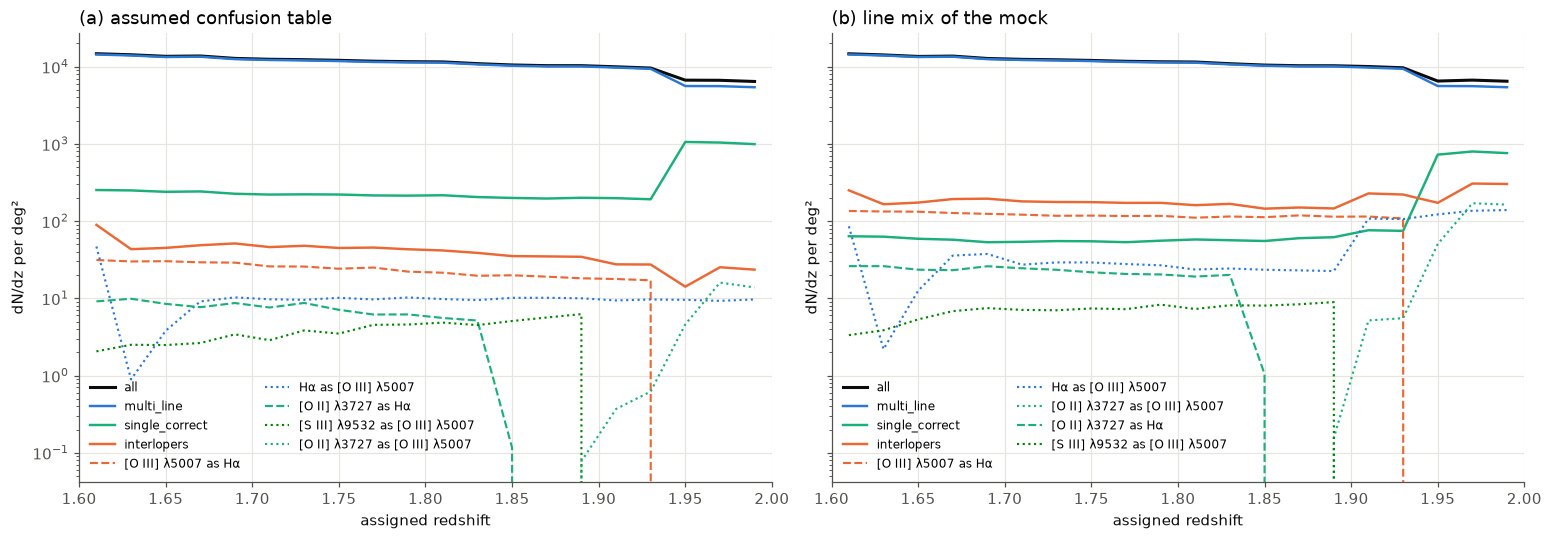

In [6]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


edges = np.linspace(1.6, 2.0, 21)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, sharey=True)
show_components(cat, "(a) assumed confusion table", axes[0], edges)
show_components(cat_emp, "(b) line mix of the mock", axes[1], edges)
plt.show()


The two catalogs share their 11.08 M multi-line galaxies (96.6–96.8 %):

* **(a) The assumed table** gives 41,672 interlopers (0.36 %), 5 % of each of the five potential pairs: 20,937 [O III]
  taken for Hα, 11,213 Hα taken for [O III], 4,664 [O II] taken for Hα, and 3,028 [S III] λ9532 and 1,830 [O II] taken
  for [O III]. These are exactly the kinds the proposal lists.
* **(b) The line mix of the mock** gives 198,766 interlopers (1.7 %), five times as many. At 17 000–19 300 Å [O III]
  from z > 2.4 makes 59–68 % of the single lines, so 104,961 of them are taken for Hα. The others are 53,735 Hα taken
  for [O III], 20,375 and 14,224 [O II], 5,391 [S III] λ9532, and 80 Paα (z < 0.03) taken for Hα. Only 46 % of the
  single-line galaxies inside the range keep a correct redshift (169,864 of 369,242).

In both catalogs the single-line galaxies with a correct redshift jump at z = 1.94, where Hα leaves the grism and
[O III] is often alone. The [O III] taken for Hα stop there, since no galaxy is assigned Hα above z = 1.94.

## The files

As in notebook 01: `<name>.hdf5`, `<name>_summary.json` and `<name>_proposal.npz` in each directory, with the default
name `all_z1p6_2p0`.

In [7]:
for d in ("all_z1p6_2p0_matrix", "all_z1p6_2p0_empirical"):
    print(d + ":", ", ".join(sorted(p.name for p in (OUT / d).iterdir() if p.is_file())))
back = Catalog.read(OUT / "all_z1p6_2p0_empirical" / "all_z1p6_2p0.hdf5")
print(f"read back: {len(back):,} galaxies; columns {', '.join(back.columns)}")


all_z1p6_2p0_matrix: all_z1p6_2p0.hdf5, all_z1p6_2p0_proposal.npz, all_z1p6_2p0_summary.json
all_z1p6_2p0_empirical: all_z1p6_2p0.hdf5, all_z1p6_2p0_proposal.npz, all_z1p6_2p0_summary.json
read back: 11,446,192 galaxies; columns gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome, line_true, line_assigned, n_det


## Summary

* At 1.6 < z < 2.0 the catalog of every galaxy (`line="all"`) holds 11.45 M galaxies at flux limits 1.5 / 0.6. Of them
  3.2 % are single-line, and five potential pairs could make at most 6.8 % of the catalog.
* With S/N 5 / 2 it holds 18.3 M galaxies, at most 14.9 % interlopers, mostly Hα at z ≈ 1 taken for [O III].
* The assumed table gives 41,672 interlopers (0.36 %), the line mix of the mock 198,766 (1.7 %), half of them [O III]
  at z > 2.4 taken for Hα.
* The notebook ran in 2.8 minutes on a CPU node.